In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("Train.csv")
df.shape
display(df.head())

,ID,country,owner_age,attitude_stable_business_environment,attitude_worried_shutdown,compliance_income_tax,perception_insurance_doesnt_cover_losses,perception_cannot_afford_insurance,personal_income,business_expenses,...,has_internet_banking,has_debit_card,future_risk_theft_stock,business_age_months,medical_insurance,funeral_insurance,motivation_make_more_money,uses_friends_family_savings,uses_informal_lender,Target
0,ID_3CFL0U,eswatini,63.0,Yes,No,No,No,Yes,3000.0,6000.0,...,Never had,Never had,NaN,6.0,Never had,Used to have but don’t have now,NaN,Never had,Never had,Low
1,ID_XWI7G3,zimbabwe,39.0,No,Yes,Yes,No,Yes,NaN,NaN,...,NaN,NaN,No,3.0,Never had,Never had,NaN,NaN,NaN,Medium
2,ID_TY93LV,malawi,34.0,Don’t know or N/A,No,No,Don't know,Yes,30000.0,6000.0,...,Never had,Never had,Yes,NaN,NaN,NaN,Yes,NaN,NaN,Low
3,ID_9OP2C8,malawi,28.0,Yes,No,No,No,No,180000.0,60000.0,...,Never had,Never had,No,NaN,NaN,NaN,Yes,Never had,Have now,Low
4,ID_13REYS,zimbabwe,43.0,Yes,No,No,Yes,Yes,50.0,2400.0,...,NaN,NaN,No,0.0,Never had,Never had,Yes,NaN,NaN,Low


In [ ]:
df.describe()

,owner_age,personal_income,business_expenses,business_turnover,business_age_years,business_age_months
count,9618.000000,9.509000e+03,9.389000e+03,9.402000e+03,9366.000000,5507.000000
mean,41.705344,2.627345e+05,4.583838e+05,1.348210e+06,7.030536,3.636281
std,13.314010,2.566268e+06,6.184746e+06,8.804741e+06,7.650349,3.386488
min,18.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,32.000000,3.000000e+02,7.000000e+02,1.500000e+03,2.000000,0.000000
50%,40.000000,2.000000e+03,3.000000e+03,6.000000e+03,4.000000,3.000000
75%,50.000000,2.500000e+04,2.500000e+04,5.000000e+04,10.000000,6.000000
max,103.000000,1.500000e+08,5.000000e+08,4.200000e+08,60.000000,11.000000


In [ ]:
df.isna().sum()

,0
ID,0
country,0
owner_age,0
attitude_stable_business_environment,2
attitude_worried_shutdown,2
compliance_income_tax,4
perception_insurance_doesnt_cover_losses,5
perception_cannot_afford_insurance,5
personal_income,109
business_expenses,229


In [ ]:
df.nunique()

,0
ID,9618
country,4
owner_age,76
attitude_stable_business_environment,3
attitude_worried_shutdown,3
compliance_income_tax,4
perception_insurance_doesnt_cover_losses,3
perception_cannot_afford_insurance,3
personal_income,697
business_expenses,894


Visuals


/tmp/ipykernel_2530/3048305839.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Target', order=df['Target'].value_counts().index, palette='viridis')


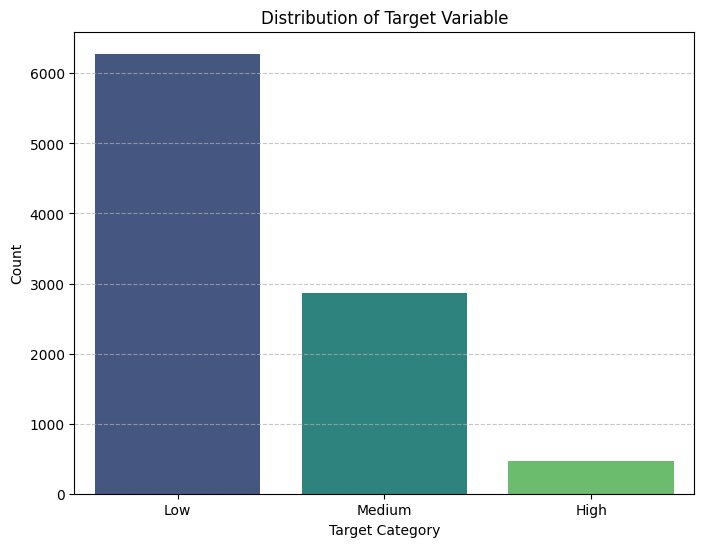

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the distribution of the 'Target' variable
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Target', order=df['Target'].value_counts().index, palette='viridis')
plt.title('Distribution of Target Variable')
plt.xlabel('Target Category')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 1. Missing Values Visualization



/tmp/ipykernel_2530/2677083334.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_percentage.index, y=missing_percentage.values, palette='viridis')


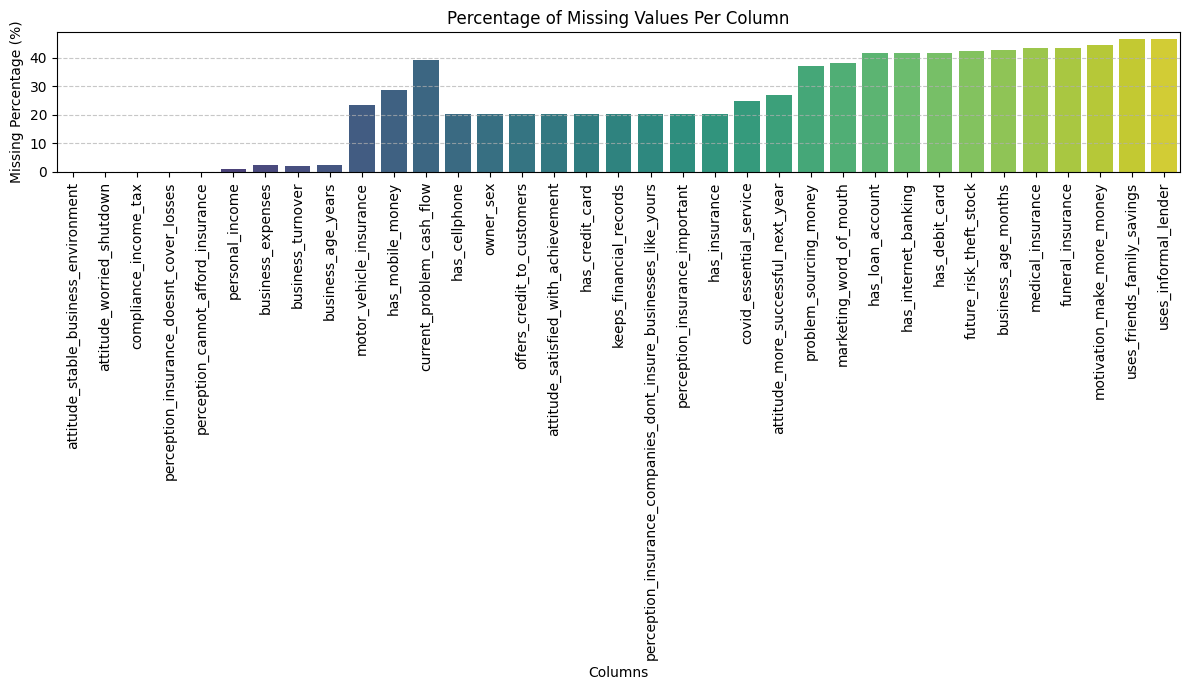


### 2. Target Distribution Across Countries



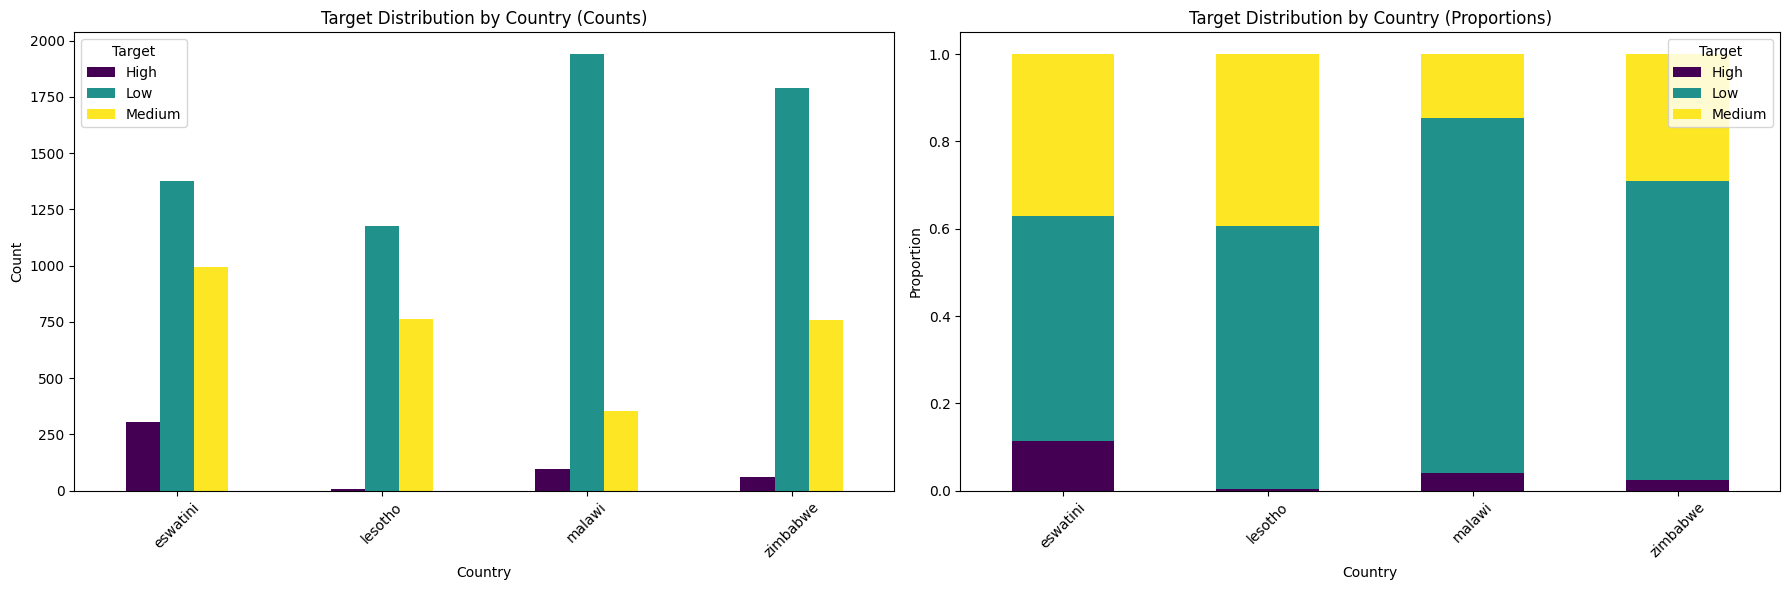


### 3. Skewness of Numerical Columns

Skewness of numerical columns:



,0
business_expenses,60.469325
personal_income,33.563069
business_turnover,23.544172
business_age_years,2.156752
business_age_months,0.682402
owner_age,0.659190



Histograms for the 5 most skewed numerical columns:



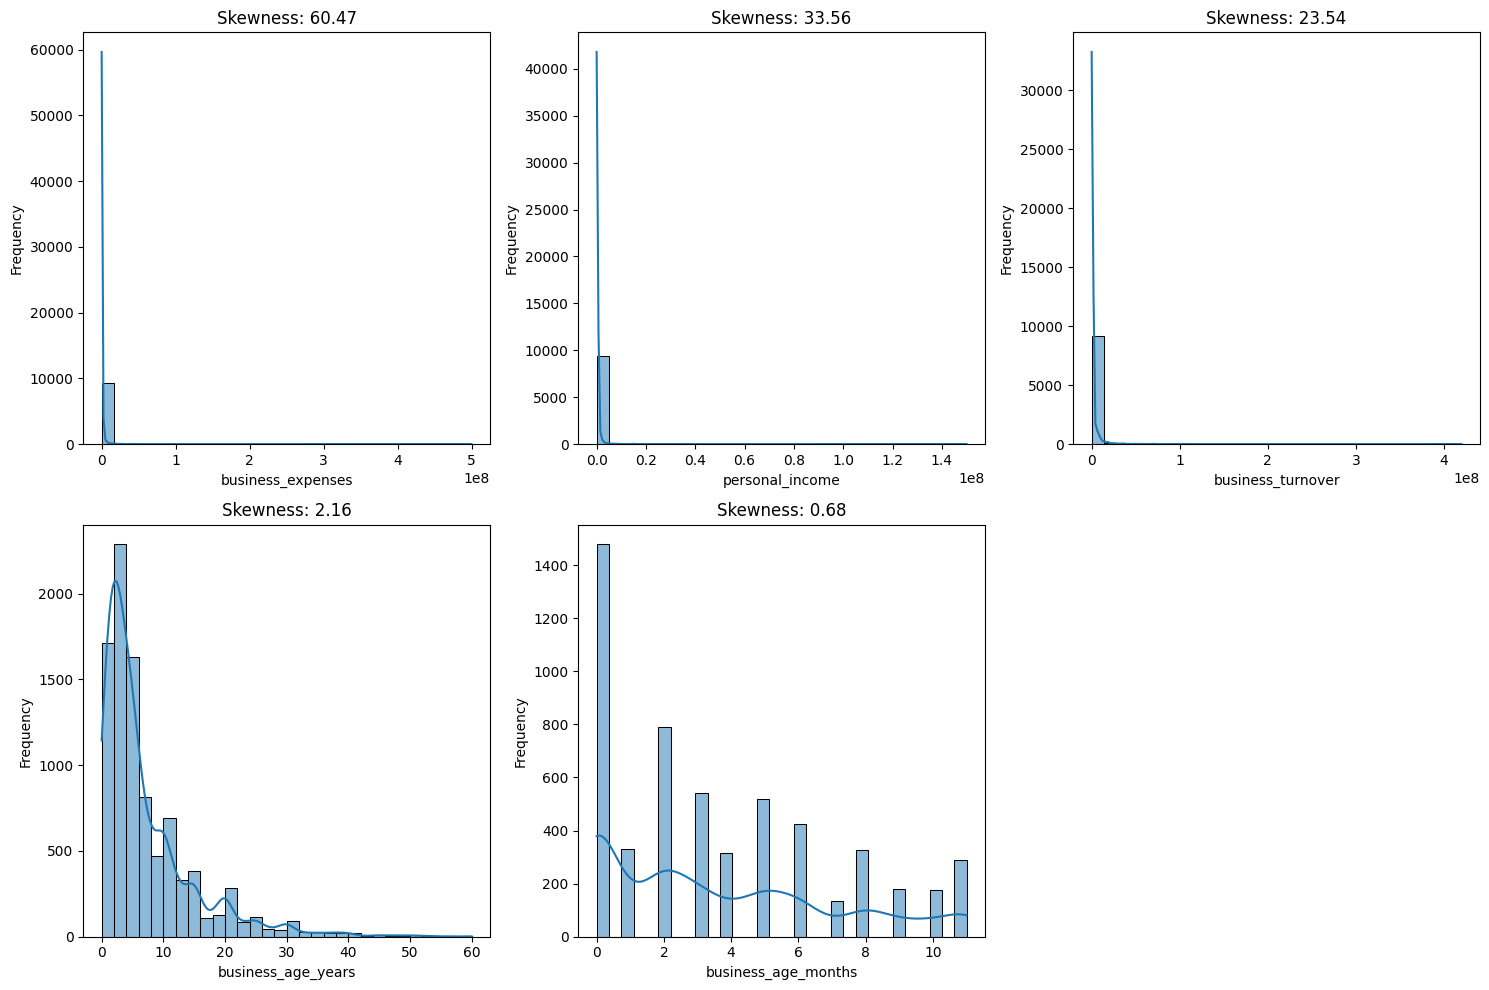

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Missing Values Visualization ---
print("### 1. Missing Values Visualization\n")
missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0]
missing_percentage = (missing_data / len(df)) * 100

if not missing_percentage.empty:
    plt.figure(figsize=(12, 7))
    sns.barplot(x=missing_percentage.index, y=missing_percentage.values, palette='viridis')
    plt.title('Percentage of Missing Values Per Column')
    plt.xlabel('Columns')
    plt.ylabel('Missing Percentage (%)')
    plt.xticks(rotation=90)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the DataFrame.")

# --- 2. Target Distribution Across Countries ---
print("\n### 2. Target Distribution Across Countries\n")
country_target_crosstab = pd.crosstab(df['country'], df['Target'])

# Normalize to show proportions within each country
country_target_crosstab_norm = country_target_crosstab.div(country_target_crosstab.sum(1), axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

country_target_crosstab.plot(kind='bar', stacked=False, ax=ax1, cmap='viridis')
ax1.set_title('Target Distribution by Country (Counts)')
ax1.set_xlabel('Country')
ax1.set_ylabel('Count')
ax1.tick_params(axis='x', rotation=45)
ax1.legend(title='Target')

country_target_crosstab_norm.plot(kind='bar', stacked=True, ax=ax2, cmap='viridis')
ax2.set_title('Target Distribution by Country (Proportions)')
ax2.set_xlabel('Country')
ax2.set_ylabel('Proportion')
ax2.tick_params(axis='x', rotation=45)
ax2.legend(title='Target')

plt.tight_layout()
plt.show()

# --- 3. Skewness of Numerical Columns ---
print("\n### 3. Skewness of Numerical Columns\n")

current_num_cols = df.select_dtypes(include=np.number).columns.tolist()

skewness_values = df[current_num_cols].skew().sort_values(ascending=False)
print("Skewness of numerical columns:\n")
display(skewness_values)

# Plot histograms for the top 5 most skewed numerical columns
print("\nHistograms for the 5 most skewed numerical columns:\n")
plt.figure(figsize=(15, 10))
for i, col in enumerate(skewness_values.head(5).index):
    plt.subplot(2, 3, i + 1)
    sns.histplot(df[col].dropna(), kde=True, bins=30)
    plt.title(f'Skewness: {skewness_values[col]:.2f}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


Handeling inconsistancy and missingness

In [ ]:
df = df.replace('\u200e', '', regex = True)

In [ ]:
cat_col = df.select_dtypes(include="object").columns.drop( 'ID')

for col in cat_col:
    df[col] = df[col].str.lower().str.strip()

    df[col] = df[col].map(
        lambda x: "Yes" if str(x).startswith("yes")
        else "Don't know" if str(x).startswith("do")
        else "No" if str(x).startswith("no")
        else "used to have but don't have now" if str(x).startswith("used")
        else x
    )

In [ ]:
df['has_credit_card'].unique()

array(['never had', nan, 'have now', "Don't know",
       "used to have but don't have now"], dtype=object)

In [ ]:
df_missing = (df[cat_col].isnull().sum() / len(df)) * 100
df_missing

,0
country,0.000000
attitude_stable_business_environment,0.020794
attitude_worried_shutdown,0.020794
compliance_income_tax,0.041589
perception_insurance_doesnt_cover_losses,0.051986
perception_cannot_afford_insurance,0.051986
motor_vehicle_insurance,23.331254
has_mobile_money,28.602620
current_problem_cash_flow,39.280516
has_cellphone,20.212102


In [ ]:
num_col = df.select_dtypes(include="number").columns
df_missing = (df[num_col].isnull().sum() / len(df)) * 100
df_missing


,0
owner_age,0.000000
personal_income,1.133292
business_expenses,2.380952
business_turnover,2.245789
business_age_years,2.620087
business_age_months,42.742774


In [ ]:
df['country'].value_counts()

,count
country,
eswatini,2674
zimbabwe,2612
malawi,2388
lesotho,1944


In [ ]:
df['Target'].value_counts()

,count
Target,
low,6280
medium,2868
high,470


In [ ]:
pd.crosstab(df['country'], df['Target'])

Target,high,low,medium
country,,,
eswatini,307,1375,992
lesotho,6,1174,764
malawi,96,1940,352
zimbabwe,61,1791,760


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9618 entries, 0 to 9617
Data columns (total 39 columns):
 #   Column                                                            Non-Null Count  Dtype  
---  ------                                                            --------------  -----  
 0   ID                                                                9618 non-null   object 
 1   country                                                           9618 non-null   object 
 2   owner_age                                                         9618 non-null   float64
 3   attitude_stable_business_environment                              9616 non-null   object 
 4   attitude_worried_shutdown                                         9616 non-null   object 
 5   compliance_income_tax                                             9614 non-null   object 
 6   perception_insurance_doesnt_cover_losses                          9613 non-null   object 
 7   perception_cannot_afford_insuranc

In [ ]:
# Reverse log1p transformation for these specific columns to perform arithmetic on original values
df['business_age_years_original'] = np.expm1(df['business_age_years'])
df['business_age_months_original'] = np.expm1(df['business_age_months'])

# Create the engineered feature: total business age in months
# NaNs in business_age_months_original will correctly propagate to business_age_total_months
df['business_age_total_months'] = (df['business_age_years_original'] * 12) + df['business_age_months_original']

# Apply log1p transformation to the new combined feature
#df['business_age_total_months'] = np.log1p(df['business_age_total_months'])

# Drop the original 'business_age_years' and 'business_age_months'
# and the temporary original columns
df.drop(columns=['business_age_years', 'business_age_months', 'business_age_years_original', 'business_age_months_original'], inplace=True)

print("DataFrame head after creating 'business_age_total_months' and dropping originals:")
display(df.head())

print("Missing values summary after feature engineering:")
display(df.isna().sum())

DataFrame head after creating 'business_age_total_months' and dropping originals:


,ID,country,owner_age,attitude_stable_business_environment,attitude_worried_shutdown,compliance_income_tax,perception_insurance_doesnt_cover_losses,perception_cannot_afford_insurance,personal_income,business_expenses,...,has_internet_banking,has_debit_card,future_risk_theft_stock,medical_insurance,funeral_insurance,motivation_make_more_money,uses_friends_family_savings,uses_informal_lender,Target,business_age_total_months
0,ID_3CFL0U,eswatini,63.0,Yes,No,No,No,Yes,3000.0,6000.0,...,never had,never had,NaN,never had,used to have but don't have now,NaN,never had,never had,low,1.443164e+07
1,ID_XWI7G3,zimbabwe,39.0,No,Yes,Yes,No,Yes,NaN,NaN,...,NaN,NaN,No,never had,never had,NaN,NaN,NaN,medium,3.922822e+07
2,ID_TY93LV,malawi,34.0,Don't know,No,No,Don't know,Yes,30000.0,6000.0,...,never had,never had,Yes,NaN,NaN,Yes,NaN,NaN,low,NaN
3,ID_9OP2C8,malawi,28.0,Yes,No,No,No,No,180000.0,60000.0,...,never had,never had,No,NaN,NaN,Yes,never had,have now,low,NaN
4,ID_13REYS,zimbabwe,43.0,Yes,No,No,Yes,Yes,50.0,2400.0,...,NaN,NaN,No,never had,never had,Yes,NaN,NaN,low,2.290264e+02


Missing values summary after feature engineering:


,0
ID,0
country,0
owner_age,0
attitude_stable_business_environment,2
attitude_worried_shutdown,2
compliance_income_tax,4
perception_insurance_doesnt_cover_losses,5
perception_cannot_afford_insurance,5
personal_income,109
business_expenses,229


In [ ]:
# Redefine num_col to ensure it's up-to-date with current numerical columns in df
num_col = df.select_dtypes(include='number').columns

# Fill any potential missing values in numerical columns with the median of each column, grouped by country
for col in num_col:
    df[col] = df.groupby('country')[col].transform(lambda x: x.fillna(x.median()))

df

,ID,country,owner_age,attitude_stable_business_environment,attitude_worried_shutdown,compliance_income_tax,perception_insurance_doesnt_cover_losses,perception_cannot_afford_insurance,personal_income,business_expenses,...,has_internet_banking,has_debit_card,future_risk_theft_stock,medical_insurance,funeral_insurance,motivation_make_more_money,uses_friends_family_savings,uses_informal_lender,Target,business_age_total_months
0,ID_3CFL0U,eswatini,63.0,Yes,No,No,No,Yes,3000.0,6000.0,...,never had,never had,NaN,never had,used to have but don't have now,NaN,never had,never had,low,1.443164e+07
1,ID_XWI7G3,zimbabwe,39.0,No,Yes,Yes,No,Yes,150.0,1200.0,...,NaN,NaN,No,never had,never had,NaN,NaN,NaN,medium,3.922822e+07
2,ID_TY93LV,malawi,34.0,Don't know,No,No,Don't know,Yes,30000.0,6000.0,...,never had,never had,Yes,NaN,NaN,Yes,NaN,NaN,low,NaN
3,ID_9OP2C8,malawi,28.0,Yes,No,No,No,No,180000.0,60000.0,...,never had,never had,No,NaN,NaN,Yes,never had,have now,low,NaN
4,ID_13REYS,zimbabwe,43.0,Yes,No,No,Yes,Yes,50.0,2400.0,...,NaN,NaN,No,never had,never had,Yes,NaN,NaN,low,2.290264e+02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9613,ID_D7NC2D,lesotho,31.0,Yes,No,No,Don't know,Don't know,2000.0,800.0,...,NaN,NaN,NaN,NaN,NaN,No,have now,never had,medium,NaN
9614,ID_NT06RL,malawi,64.0,Don't know,Don't know,Yes,No,No,10000000.0,5000000.0,...,never had,have now,Yes,NaN,NaN,No,NaN,NaN,high,NaN
9615,ID_4TVWA3,zimbabwe,43.0,Yes,No,No,Yes,No,450.0,1200.0,...,NaN,NaN,No,have now,have now,NaN,NaN,NaN,medium,3.000577e+03
9616,ID_3U3S2Z,zimbabwe,38.0,Yes,Yes,No,No,Yes,2000.0,1200.0,...,NaN,NaN,No,never had,never had,NaN,NaN,NaN,low,4.829146e+03


In [ ]:
df['total_missing'] = df.isna().sum(axis=1)

In [ ]:

cat_cols_to_fill = [col for col in cat_col if col in df.columns]
df[cat_cols_to_fill] = df[cat_cols_to_fill].fillna('missing')

In [ ]:
df = df.drop(columns=['ID'])
df

,country,owner_age,attitude_stable_business_environment,attitude_worried_shutdown,compliance_income_tax,perception_insurance_doesnt_cover_losses,perception_cannot_afford_insurance,personal_income,business_expenses,business_turnover,...,has_debit_card,future_risk_theft_stock,medical_insurance,funeral_insurance,motivation_make_more_money,uses_friends_family_savings,uses_informal_lender,Target,business_age_total_months,total_missing
0,eswatini,63.0,Yes,No,No,No,Yes,3000.0,6000.0,7000.0,...,never had,missing,never had,used to have but don't have now,missing,never had,never had,low,1.443164e+07,2
1,zimbabwe,39.0,No,Yes,Yes,No,Yes,150.0,1200.0,3000.0,...,missing,No,never had,never had,missing,missing,missing,medium,3.922822e+07,10
2,malawi,34.0,Don't know,No,No,Don't know,Yes,30000.0,6000.0,13000.0,...,never had,Yes,missing,missing,Yes,missing,missing,low,NaN,7
3,malawi,28.0,Yes,No,No,No,No,180000.0,60000.0,30000.0,...,never had,No,missing,missing,Yes,never had,have now,low,NaN,5
4,zimbabwe,43.0,Yes,No,No,Yes,Yes,50.0,2400.0,1800.0,...,missing,No,never had,never had,Yes,missing,missing,low,2.290264e+02,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9613,lesotho,31.0,Yes,No,No,Don't know,Don't know,2000.0,800.0,500.0,...,missing,missing,missing,missing,No,have now,never had,medium,NaN,17
9614,malawi,64.0,Don't know,Don't know,Yes,No,No,10000000.0,5000000.0,200000000.0,...,have now,Yes,missing,missing,No,missing,missing,high,NaN,7
9615,zimbabwe,43.0,Yes,No,No,Yes,No,450.0,1200.0,3000.0,...,missing,No,have now,have now,missing,missing,missing,medium,3.000577e+03,10
9616,zimbabwe,38.0,Yes,Yes,No,No,Yes,2000.0,1200.0,3000.0,...,missing,No,never had,never had,missing,missing,missing,low,4.829146e+03,11


In [ ]:
df.isna().sum()

,0
country,0
owner_age,0
attitude_stable_business_environment,0
attitude_worried_shutdown,0
compliance_income_tax,0
perception_insurance_doesnt_cover_losses,0
perception_cannot_afford_insurance,0
personal_income,0
business_expenses,0
business_turnover,0


Log and training


In [ ]:
# Redefine num_col after dropping columns to ensure it only contains existing numerical columns
num_col = df.select_dtypes(include="number").columns
df[num_col] = np.log1p(df[num_col])

### Feature Engineering: Creating New Features

We will create several new features to potentially capture more complex relationships within the data:

1.  **`profit_ratio`**: Calculated as `(business_turnover - business_expenses) / (business_turnover + 1)`. This provides a normalized measure of business profitability.
2.  **`income_to_expense_ratio`**: Calculated as `personal_income / (business_expenses + 1)`. This reflects the individual's personal financial capacity relative to business costs.
3.  **`has_multiple_insurance`**: A count of how many types of insurance (motor vehicle, medical, funeral) a business has.
4.  **`has_multiple_financial_products`**: A count of various financial products (mobile money, credit card, loan account, internet banking, debit card) a business uses.

These new features will be added to the DataFrame and then the numerical and categorical column lists will be updated to ensure they are processed by the pipeline.

In [ ]:
'''# Calculate profit_ratio, handling potential division by zero
df['profit_ratio'] = (df['business_turnover'] - df['business_expenses']) / (df['business_turnover'] + 1)

# Calculate income_to_expense_ratio, handling potential division by zero
df['income_to_expense_ratio'] = df['personal_income'] / (df['business_expenses'] + 1)

# Create 'has_multiple_insurance' feature (count of 'Yes' in insurance-related columns)
insurance_cols = [
    'motor_vehicle_insurance',
    'medical_insurance',
    'funeral_insurance'
]
# Convert 'Yes' to 1 and others (No, Don't know, missing) to 0 for counting
for col in insurance_cols:
    df[f'{col}_binary'] = df[col].apply(lambda x: 1 if x == 'yes' else 0)
df['has_multiple_insurance'] = df[[f'{col}_binary' for col in insurance_cols]].sum(axis=1)
df.drop(columns=[f'{col}_binary' for col in insurance_cols], inplace=True)

# Create 'has_multiple_financial_products' feature
financial_product_cols = [
    'has_mobile_money',
    'has_credit_card',
    'has_loan_account',
    'has_internet_banking',
    'has_debit_card'
]
for col in financial_product_cols:
    df[f'{col}_binary'] = df[col].apply(lambda x: 1 if x == 'have now' or x == 'yes' else 0)
df['has_multiple_financial_products'] = df[[f'{col}_binary' for col in financial_product_cols]].sum(axis=1)
df.drop(columns=[f'{col}_binary' for col in financial_product_cols], inplace=True)

print("New features created and added to the DataFrame. Displaying head with new features:")
display(df.head())'''


'# Calculate profit_ratio, handling potential division by zero\ndf[\'profit_ratio\'] = (df[\'business_turnover\'] - df[\'business_expenses\']) / (df[\'business_turnover\'] + 1)\n\n# Calculate income_to_expense_ratio, handling potential division by zero\ndf[\'income_to_expense_ratio\'] = df[\'personal_income\'] / (df[\'business_expenses\'] + 1)\n\n# Create \'has_multiple_insurance\' feature (count of \'Yes\' in insurance-related columns)\ninsurance_cols = [\n    \'motor_vehicle_insurance\',\n    \'medical_insurance\',\n    \'funeral_insurance\'\n]\n# Convert \'Yes\' to 1 and others (No, Don\'t know, missing) to 0 for counting\nfor col in insurance_cols:\n    df[f\'{col}_binary\'] = df[col].apply(lambda x: 1 if x == \'yes\' else 0)\ndf[\'has_multiple_insurance\'] = df[[f\'{col}_binary\' for col in insurance_cols]].sum(axis=1)\ndf.drop(columns=[f\'{col}_binary\' for col in insurance_cols], inplace=True)\n\n# Create \'has_multiple_financial_products\' feature\nfinancial_product_cols = [\n 

In [ ]:
from sklearn.model_selection import train_test_split
from imblearn.pipeline import Pipeline # Changed from sklearn.pipeline to imblearn.pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler # Added StandardScaler for numerical processing
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import RFE
from sklearn.metrics import classification_report, f1_score
from xgboost import XGBClassifier
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, RandomizedSearchCV
import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.decomposition import PCA

# Split X and y
X = df.drop(columns=["Target"])
y = df["Target"]


le = LabelEncoder()
y_encoded = le.fit_transform(y)


# Identify categorical and numerical columns for the pipeline (based on the new X)
cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

# Train-test split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y_encoded,
    test_size=0.3,
    random_state=42,
    stratify=y_encoded
)

# Preprocessing
categorical_process = Pipeline([
    # Removed imputer as df.fillna('missing') was already applied globally
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numerical_process = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])
preprocess = ColumnTransformer([
    ("cat", categorical_process, cat_cols),
    ("num", numerical_process, num_cols)
])

rfe_estimator = RandomForestClassifier(random_state=42)

#rfe_selector = RFE(estimator=rfe_estimator, n_features_to_select=50, step=1)

# PCA step
#pca_transformer = PCA(n_components=20, random_state=42)

smote = SMOTE(
    random_state=42
)

class_weight_dict = {
    0: 1,   # low IR class  → normal weight
    1: 6,   # high IR class → 6x penalty for misclassification
    2: 3    # medium IR     → 3x penalty
}

full_sample_weights = compute_sample_weight(
    class_weight=class_weight_dict,
    y=y_encoded
)

xgb_model = XGBClassifier(
    n_estimators=800,
    max_depth=3,
    learning_rate=0.06,
    random_state=42,
    eval_metric="mlogloss",
    subsample=0.8,
    objective="multi:softmax",
    num_class=len(np.unique(y)),
    #reg_alpha=0.5,    # L1
    reg_lambda=1.0# L2
)

process = Pipeline([
    ("preprocess", preprocess),
    #("dimensionality_reduction", pca_transformer),
    #("smote", smote),
    ("model", xgb_model)
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []
y_cv_pred = np.zeros_like(y_encoded)

for fold, (train_idx, val_idx) in enumerate(cv.split(X, y_encoded)):
    print(f"\n--- Fold {fold+1} ---")
    X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
    y_train_fold, y_val_fold = y_encoded[train_idx], y_encoded[val_idx]
    sample_weights_fold = full_sample_weights[train_idx]

    process.fit(X_train_fold, y_train_fold,
                model__sample_weight=sample_weights_fold)

    # Make predictions
    fold_preds = process.predict(X_val_fold)
    y_cv_pred[val_idx] = fold_preds

    # Evaluate F1 macro score
    score = f1_score(y_val_fold, fold_preds, average='macro')
    cv_scores.append(score)
    print(f"Fold {fold+1} F1 Macro Score: {score:.4f}")


print("\nCross-validation F1 macro scores:", cv_scores)
print("Mean F1 macro:", np.mean(cv_scores))
print("Standard deviation:", np.std(cv_scores).round(4))

print("\nOverall Classification Report (Cross-Validated):")
print(classification_report(
    y_encoded,
    y_cv_pred,
    target_names=le.classes_
))


--- Fold 1 ---
Fold 1 F1 Macro Score: 0.8003

--- Fold 2 ---
Fold 2 F1 Macro Score: 0.8256

--- Fold 3 ---
Fold 3 F1 Macro Score: 0.7826

--- Fold 4 ---
Fold 4 F1 Macro Score: 0.7985

--- Fold 5 ---
Fold 5 F1 Macro Score: 0.8082

Cross-validation F1 macro scores: [0.8002613800042969, 0.8255991983053219, 0.7826157573183875, 0.798461575954904, 0.8082292360056994]
Mean F1 macro: 0.8030334295177219
Standard deviation: 0.014

Overall Classification Report (Cross-Validated):
              precision    recall  f1-score   support

        high       0.90      0.58      0.71       470
         low       0.88      0.99      0.93      6280
      medium       0.88      0.69      0.78      2868

    accuracy                           0.88      9618
   macro avg       0.89      0.75      0.80      9618
weighted avg       0.88      0.88      0.87      9618



### Confusion Matrix Analysis

To further analyze the model's performance, especially for the 'high' class, we will plot a confusion matrix based on the cross-validated predictions.

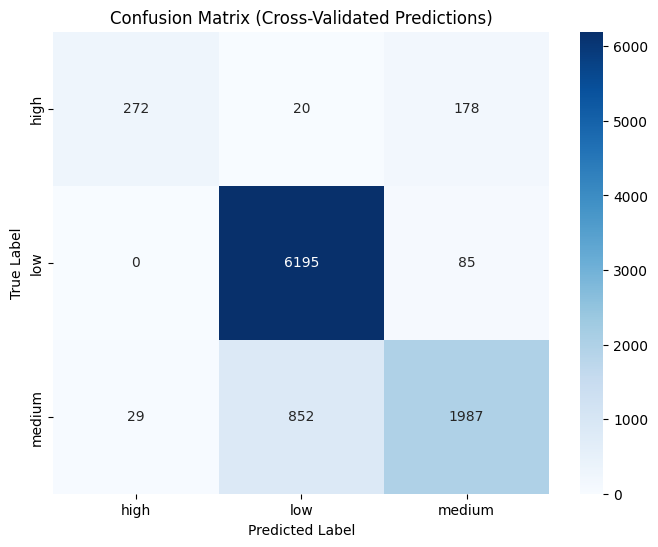

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# the confusion matrix
cm = confusion_matrix(y_encoded, y_cv_pred)

# class names from the LabelEncoder
class_names = le.classes_

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix (Cross-Validated Predictions)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


### Box Plot of Business Turnover by Target Class

This box plot illustrates the distribution of `business_turnover` (log1p transformed) for each 'Target' class. It helps to observe how the median, spread, and outliers of business turnover vary between businesses categorized as 'high', 'medium', or 'low' risk.

/tmp/ipykernel_2530/1881155810.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, x='Target', y='business_turnover', order=df_plot['Target'].value_counts().index, palette='viridis')


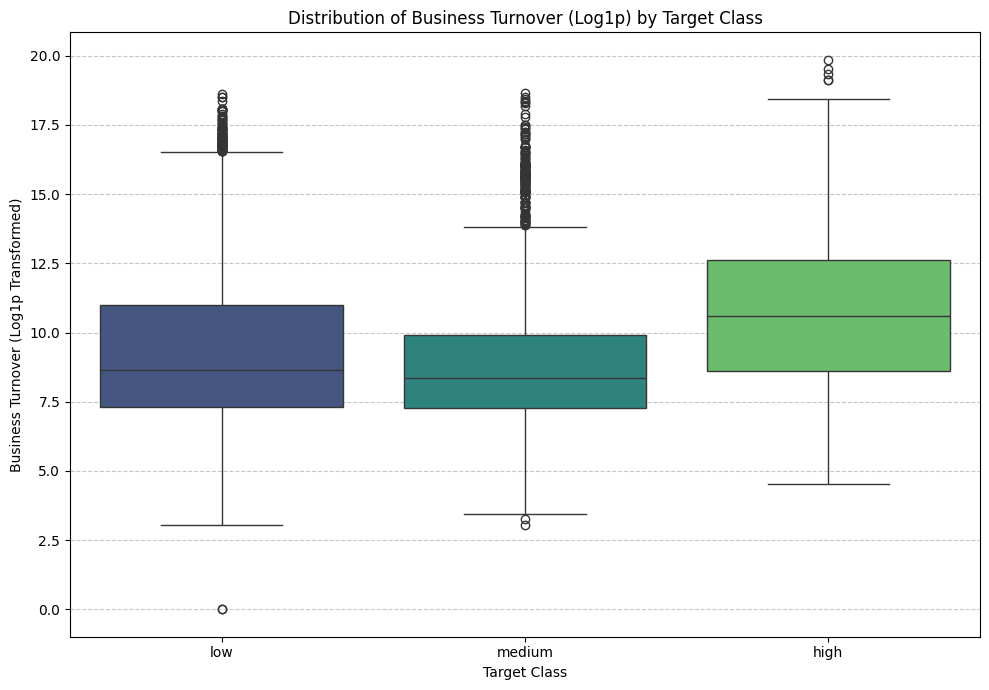

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


# Reload the original data
df_plot = pd.read_csv("Train.csv")

# Apply character replacement (from sQstXXcAisk8)
df_plot = df_plot.replace('\u200e', '', regex = True)

# Define original categorical columns before 'ID' drop for cleaning
temp_df_for_cols = pd.read_csv("/content/Train.csv")
original_cat_cols_before_id_drop = temp_df_for_cols.select_dtypes(include="object").columns.drop('ID')
del temp_df_for_cols # Clean up temporary DataFrame

# Apply categorical cleaning and mapping (from IXiK4CaPgd3v)
for col in original_cat_cols_before_id_drop:
    df_plot[col] = df_plot[col].str.lower().str.strip()
    df_plot[col] = df_plot[col].map(
        lambda x: "Yes" if str(x).startswith("yes")
        else "Don't know" if str(x).startswith("do")
        else "No" if str(x).startswith("no")
        else "used to have but don't have now" if str(x).startswith("used")
        else x
    )

df_plot = df_plot.drop(columns=['ID'])

original_numerical_features_names = [
    'owner_age', 'personal_income', 'business_expenses',
    'business_turnover', 'business_age_years', 'business_age_months'
]
original_categorical_features_names = df_plot.select_dtypes(include='object').columns.drop('Target').tolist()

df_plot['business_age_years_original'] = np.expm1(df_plot['business_age_years'])
df_plot['business_age_months_original'] = np.expm1(df_plot['business_age_months'])

df_plot['business_age_total_months'] = (df_plot['business_age_years_original'] * 12) + df_plot['business_age_months_original']


df_plot.drop(columns=['business_age_years', 'business_age_months', 'business_age_years_original', 'business_age_months_original'], inplace=True)

current_numerical_features = [
    'owner_age', 'personal_income', 'business_expenses',
    'business_turnover', 'business_age_total_months'
]

for col in current_numerical_features:
    df_plot[col] = df_plot.groupby('country')[col].transform(lambda x: x.fillna(x.median()))

df_plot[original_categorical_features_names] = df_plot[original_categorical_features_names].fillna('missing')

df_plot[current_numerical_features] = np.log1p(df_plot[current_numerical_features])


# --- Generate the box plot for business_turnover ---
plt.figure(figsize=(10, 7))
sns.boxplot(data=df_plot, x='Target', y='business_turnover', order=df_plot['Target'].value_counts().index, palette='viridis')
plt.title('Distribution of Business Turnover (Log1p) by Target Class')
plt.xlabel('Target Class')
plt.ylabel('Business Turnover (Log1p Transformed)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('business_turnover_boxplot.png')
plt.show()

DataFrame re-prepared with original features only (imputed, categorical cleaned, numerical log1p transformed).


,country,owner_age,attitude_stable_business_environment,attitude_worried_shutdown,compliance_income_tax,perception_insurance_doesnt_cover_losses,perception_cannot_afford_insurance,personal_income,business_expenses,business_turnover,...,has_internet_banking,has_debit_card,future_risk_theft_stock,business_age_months,medical_insurance,funeral_insurance,motivation_make_more_money,uses_friends_family_savings,uses_informal_lender,Target
0,eswatini,4.158883,Yes,No,No,No,Yes,8.006701,8.699681,8.853808,...,never had,never had,missing,1.945910,never had,used to have but don't have now,missing,never had,never had,low
1,zimbabwe,3.688879,No,Yes,Yes,No,Yes,5.017280,7.090910,8.006701,...,missing,missing,No,1.386294,never had,never had,missing,missing,missing,medium
2,malawi,3.555348,Don't know,No,No,Don't know,Yes,10.308986,8.699681,9.472782,...,never had,never had,Yes,1.791759,missing,missing,Yes,missing,missing,low
3,malawi,3.367296,Yes,No,No,No,No,12.100718,11.002117,10.308986,...,never had,never had,No,1.791759,missing,missing,Yes,never had,have now,low
4,zimbabwe,3.784190,Yes,No,No,Yes,Yes,3.931826,7.783641,7.496097,...,missing,missing,No,0.000000,never had,never had,Yes,missing,missing,low



### Skewness of Numerical Columns (After Log Transformation and Robust Scaling)

Skewness of numerical columns after log transformation and Robust Scaling:



,0
business_turnover,0.845440
business_expenses,0.668877
personal_income,0.524987
business_age_years,0.061127
owner_age,-0.046649
business_age_months,-0.758647



Histograms for numerical columns after log transformation and Robust Scaling:



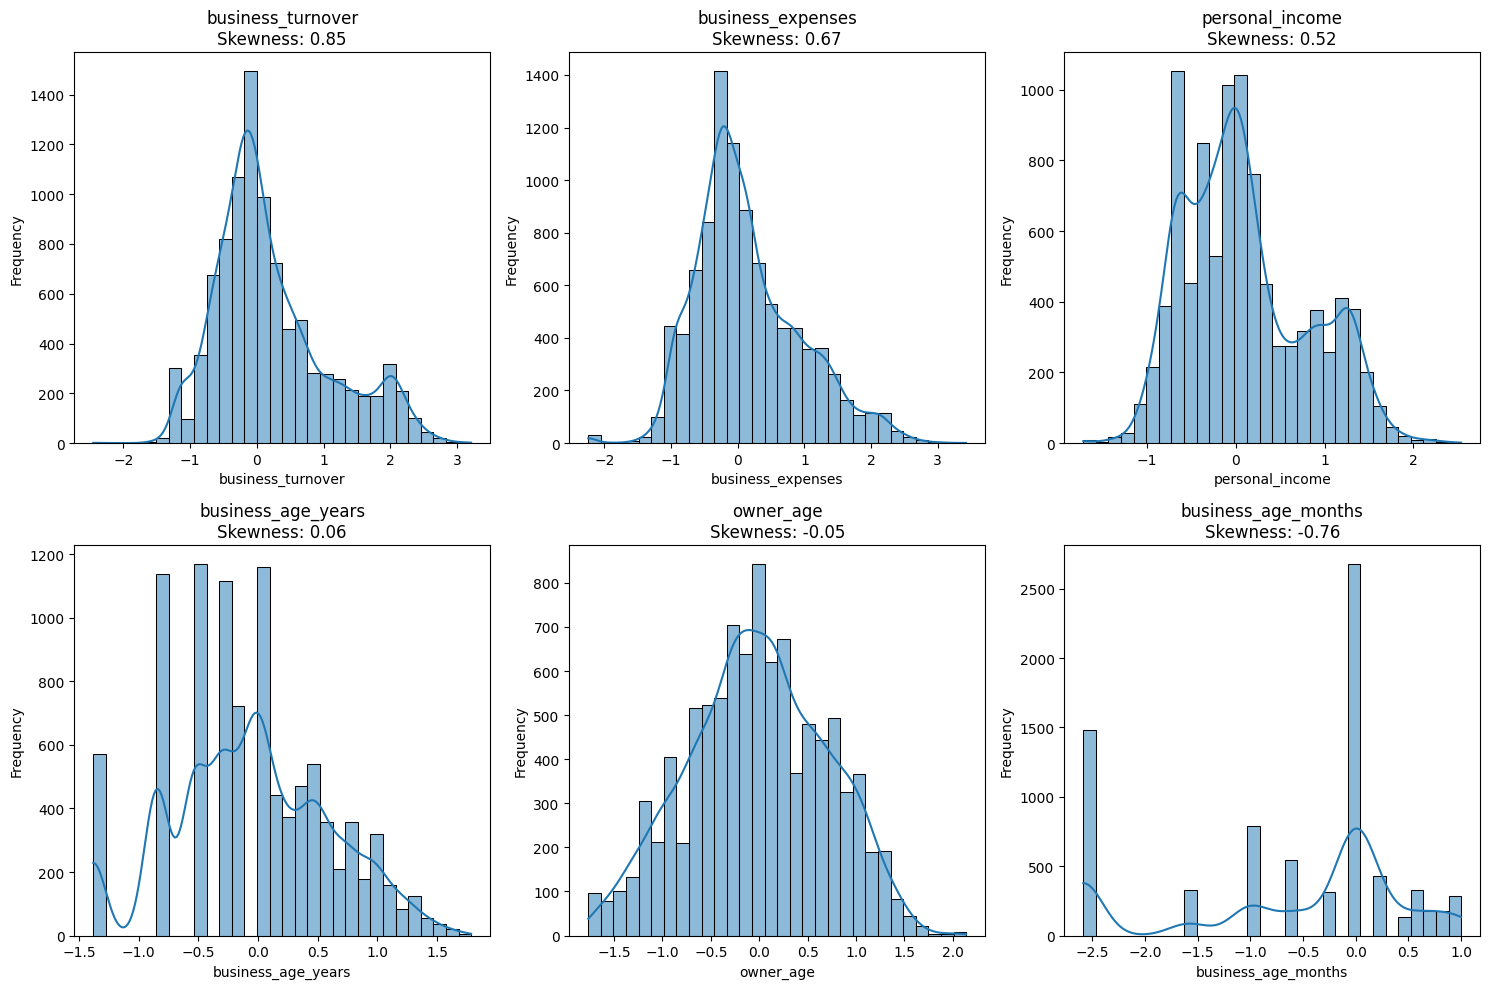


### Missing Values After Preprocessing (Original Features Only)

Unexpected missing values found:


,0
business_age_months,1944


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler


df = pd.read_csv("/content/Train.csv")

df = df.replace('\u200e', '', regex = True)

temp_df_for_cols = pd.read_csv("/content/Train.csv")
original_cat_cols_before_id_drop = temp_df_for_cols.select_dtypes(include="object").columns.drop('ID')
del temp_df_for_cols

for col in original_cat_cols_before_id_drop:
    df[col] = df[col].str.lower().str.strip()
    df[col] = df[col].map(
        lambda x: "Yes" if str(x).startswith("yes")
        else "Don't know" if str(x).startswith("do")
        else "No" if str(x).startswith("no")
        else "used to have but don't have now" if str(x).startswith("used")
        else x
    )

df = df.drop(columns=['ID'])


original_numerical_features = [
    'owner_age', 'personal_income', 'business_expenses',
    'business_turnover', 'business_age_years', 'business_age_months'
]
original_categorical_features = df.select_dtypes(include='object').columns.drop('Target').tolist()

for col in original_numerical_features:
    df[col] = df.groupby('country')[col].transform(lambda x: x.fillna(x.median()))

df[original_categorical_features] = df[original_categorical_features].fillna('missing')

df[original_numerical_features] = np.log1p(df[original_numerical_features])

print("DataFrame re-prepared with original features only (imputed, categorical cleaned, numerical log1p transformed).")
display(df.head())

print("\n### Skewness of Numerical Columns (After Log Transformation and Robust Scaling)\n")

numerical_data_logged = df[original_numerical_features].copy()

scaler = RobustScaler()
numerical_data_scaled = scaler.fit_transform(numerical_data_logged)

# Convert back to DataFrame for easier handling and to retain column names
numerical_data_scaled_df = pd.DataFrame(numerical_data_scaled, columns=original_numerical_features)

skewness_values_scaled = numerical_data_scaled_df.skew().sort_values(ascending=False)
print("Skewness of numerical columns after log transformation and Robust Scaling:\n")
display(skewness_values_scaled)

print("\nHistograms for numerical columns after log transformation and Robust Scaling:\n")
plt.figure(figsize=(15, 10))
for i, col in enumerate(skewness_values_scaled.index):
    plt.subplot(2, 3, i + 1)
    sns.histplot(numerical_data_scaled_df[col], kde=True, bins=30)
    plt.title(f'{col}\nSkewness: {skewness_values_scaled[col]:.2f}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


# Missing Values Visualization
print("\n### Missing Values After Preprocessing (Original Features Only)\n")
missing_data_after_prep = df.isnull().sum()
missing_data_after_prep = missing_data_after_prep[missing_data_after_prep > 0]
if not missing_data_after_prep.empty:
    print("Unexpected missing values found:")
    display(missing_data_after_prep)
else:
    print("No missing values found in the DataFrame after preprocessing.")



In [ ]:
from sklearn.model_selection import train_test_split
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import RFE
from sklearn.metrics import classification_report, f1_score
from xgboost import XGBClassifier
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, RandomizedSearchCV
import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.decomposition import PCA

X = df.drop(columns=["Target"])
y = df["Target"]


le = LabelEncoder()
y_encoded = le.fit_transform(y)


cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

# Train-test split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y_encoded,
    test_size=0.3,
    random_state=42,
    stratify=y_encoded
)

# Preprocessing
categorical_process = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numerical_process = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])
preprocess = ColumnTransformer([
    ("cat", categorical_process, cat_cols),
    ("num", numerical_process, num_cols)
])

rfe_estimator = RandomForestClassifier(random_state=42)
# RFE step (commented out, replaced by PCA)
#rfe_selector = RFE(estimator=rfe_estimator, n_features_to_select=50, step=1)

# PCA step
#pca_transformer = PCA(n_components=20, random_state=42)

smote = SMOTE(
    random_state=42
)

class_weight_dict = {
    0: 1,   # low IR class
    1: 6,   # high IR class → 6x penalty for misclassification
    2: 3    # medium IR     → 3x penalty
}


RF_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=15, # Increased max_depth to allow for better learning
    random_state=42,
    class_weight=class_weight_dict
)

xgb_model = XGBClassifier(
    n_estimators=800,
    max_depth=3,
    learning_rate=0.06,
    random_state=42,
    eval_metric="mlogloss",
    subsample=0.8,
    objective="multi:softmax",
    num_class=len(np.unique(y)),
    #reg_alpha=0.5,    # L1
    reg_lambda=1.0# L2
)

process = Pipeline([
    ("preprocess", preprocess),
    #("dimensionality_reduction", pca_transformer),
    #("smote", smote),
    ("model", xgb_model) ])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []
y_cv_pred = np.zeros_like(y_encoded)

for fold, (train_idx, val_idx) in enumerate(cv.split(X, y_encoded)):
    print(f"\n--- Fold {fold+1} ---")
    X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
    y_train_fold, y_val_fold = y_encoded[train_idx], y_encoded[val_idx]


    sample_weights_fold = np.array([class_weight_dict[label] for label in y_train_fold])

    process.fit(X_train_fold, y_train_fold, model__sample_weight=sample_weights_fold)

    # Make predictions
    fold_preds = process.predict(X_val_fold)
    y_cv_pred[val_idx] = fold_preds

    # Evaluate F1 macro score
    score = f1_score(y_val_fold, fold_preds, average='macro')
    cv_scores.append(score)
    print(f"Fold {fold+1} F1 Macro Score: {score:.4f}")


print("\nCross-validation F1 macro scores:", cv_scores)
print("Mean F1 macro:", np.mean(cv_scores))
print("Standard deviation:", np.std(cv_scores).round(4))

print("\nOverall Classification Report (Cross-Validated):")
print(classification_report(
    y_encoded,
    y_cv_pred,
    target_names=le.classes_
))



--- Fold 1 ---
Fold 1 F1 Macro Score: 0.7957

--- Fold 2 ---
Fold 2 F1 Macro Score: 0.8156

--- Fold 3 ---
Fold 3 F1 Macro Score: 0.7898

--- Fold 4 ---
Fold 4 F1 Macro Score: 0.7844

--- Fold 5 ---
Fold 5 F1 Macro Score: 0.7972

Cross-validation F1 macro scores: [0.7957109915745297, 0.8155854423891595, 0.7897895677447072, 0.7843922569787294, 0.7971692571186805]
Mean F1 macro: 0.7965295031611612
Standard deviation: 0.0106

Overall Classification Report (Cross-Validated):
              precision    recall  f1-score   support

        high       0.89      0.56      0.69       470
         low       0.88      0.99      0.93      6280
      medium       0.88      0.69      0.78      2868

    accuracy                           0.88      9618
   macro avg       0.88      0.75      0.80      9618
weighted avg       0.88      0.88      0.87      9618



### Predict on Test Data

### Quantifying Categorical Feature Importance: Cramér's V

To statistically quantify the strength of association between nominal categorical features and the target variable, we can use **Cramér's V**. It's a measure of association between two nominal variables, giving a value between 0 (no association) and 1 (complete association). A higher value indicates a stronger relationship.

First, we'll define a function to calculate Cramér's V, then apply it to all identified categorical columns against our 'Target' column.

In [ ]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    '''Calculate Cramér's V statistic for two categorical series.'''
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    # Correct for bias with the number of rows/columns
    phi2 = chi2 / n
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

current_cat_cols = df.select_dtypes(include='object').columns.tolist()
if 'ID' in current_cat_cols:
    current_cat_cols.remove('ID')
if 'Target' in current_cat_cols:
    current_cat_cols.remove('Target')

# Dictionary to store Cramér's V values
cramers_v_results = {}

for col in current_cat_cols:
    feature_series = df[col].fillna('Missing_Category')
    target_series = df['Target']

    try:
        v_score = cramers_v(feature_series, target_series)
        cramers_v_results[col] = v_score
    except ValueError as e:
        print(f"Could not calculate Cramér's V for {col}: {e}")
        cramers_v_results[col] = np.nan

# Convert results to a DataFrame for better viewing
cramers_v_df = pd.DataFrame(list(cramers_v_results.items()), columns=['Feature', "Cramér's V"])
cramers_v_df = cramers_v_df.sort_values(by="Cramér's V", ascending=False).reset_index(drop=True)

print("Cramér's V for Categorical Features vs. Target:")
display(cramers_v_df)

Cramér's V for Categorical Features vs. Target:


,Feature,Cramér's V
0,funeral_insurance,0.450036
1,has_credit_card,0.314133
2,has_loan_account,0.281003
3,motor_vehicle_insurance,0.252464
4,medical_insurance,0.244163
5,has_insurance,0.234695
6,country,0.207204
7,uses_friends_family_savings,0.182636
8,has_internet_banking,0.181649
9,has_debit_card,0.180188


### Visualizing Categorical Feature Importance: Cramér's V

The bar plot below displays the Cramér's V scores for each categorical feature against the target variable, sorted in descending order. A higher Cramér's V value indicates a stronger association between the categorical feature and the 'Target'.

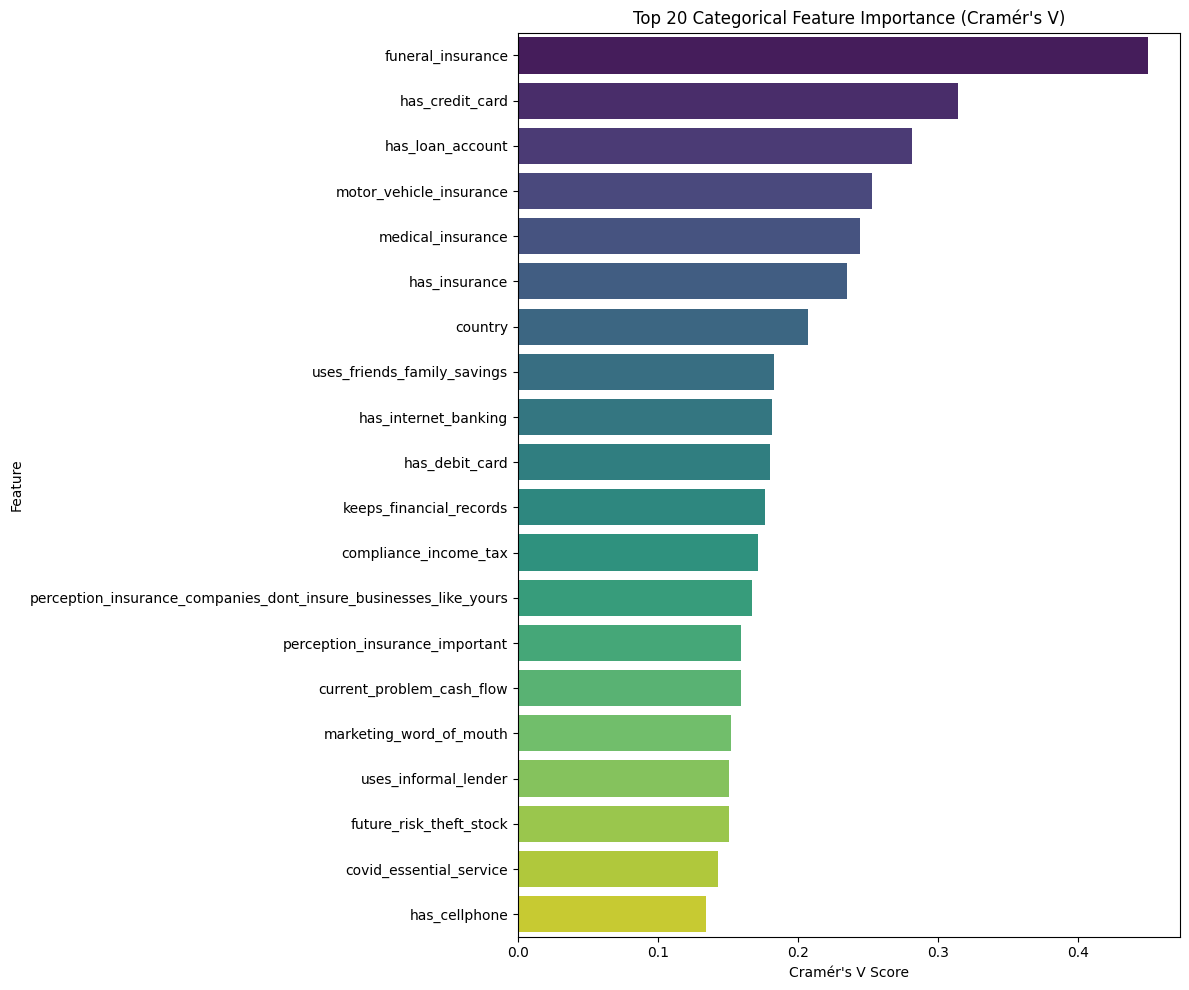

In [ ]:
plt.figure(figsize=(12, 10))
sns.barplot(x="Cramér's V", y='Feature', data=cramers_v_df.head(20), palette='viridis', hue='Feature', legend=False)
plt.title("Top 20 Categorical Feature Importance (Cramér's V)")
plt.xlabel("Cramér's V Score")
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('categorical_feature_importance.png')
plt.show()


In [ ]:
'''import pandas as pd

mixed_type_columns = {}
for col in df.columns:
    dtype = pd.api.types.infer_dtype(df[col])
    if dtype == 'mixed':
        mixed_type_columns[col] = df[col].apply(type).value_counts().index.tolist()

if mixed_type_columns:
    print("Columns with mixed data types:")
    for col, types in mixed_type_columns.items():
        print(f"- '{col}': {types}")
else:
    print("No columns with mixed data types found.")'''

'import pandas as pd\n\nmixed_type_columns = {}\nfor col in df.columns:\n    dtype = pd.api.types.infer_dtype(df[col])\n    if dtype == \'mixed\':\n        mixed_type_columns[col] = df[col].apply(type).value_counts().index.tolist()\n\nif mixed_type_columns:\n    print("Columns with mixed data types:")\n    for col, types in mixed_type_columns.items():\n        print(f"- \'{col}\': {types}")\nelse:\n    print("No columns with mixed data types found.")'

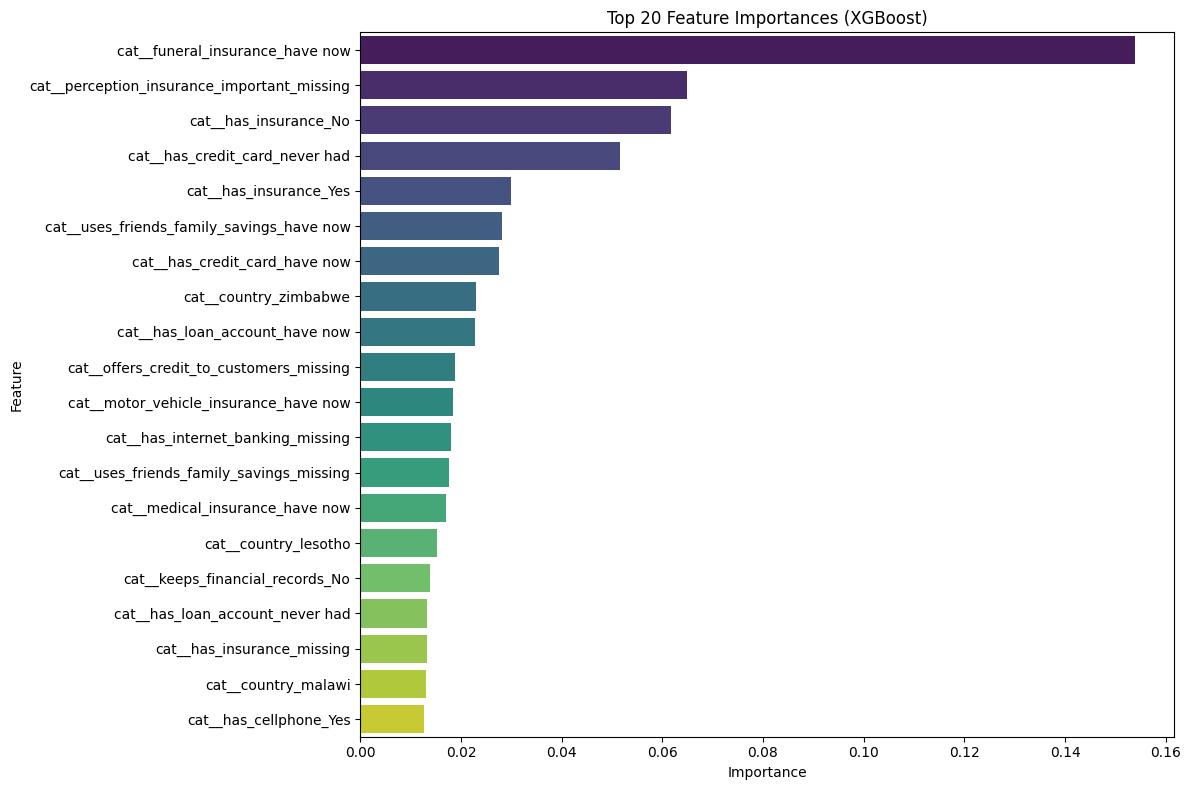

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight


df_current = pd.read_csv("/content/Train.csv")
df_current = df_current.replace('\u200e', '', regex = True)
temp_df_for_cols = pd.read_csv("/content/Train.csv")
original_cat_cols_before_id_drop = temp_df_for_cols.select_dtypes(include="object").columns.drop('ID')
del temp_df_for_cols
for col in original_cat_cols_before_id_drop:
    df_current[col] = df_current[col].str.lower().str.strip()
    df_current[col] = df_current[col].map(
        lambda x: "Yes" if str(x).startswith("yes")
        else "Don't know" if str(x).startswith("do")
        else "No" if str(x).startswith("no")
        else "used to have but don't have now" if str(x).startswith("used")
        else x
    )
df_current = df_current.drop(columns=['ID'])
original_numerical_features = [
    'owner_age', 'personal_income', 'business_expenses',
    'business_turnover', 'business_age_years', 'business_age_months'
]
original_categorical_features = df_current.select_dtypes(include='object').columns.drop('Target').tolist()
for col in original_numerical_features:
    df_current[col] = df_current.groupby('country')[col].transform(lambda x: x.fillna(x.median()))
df_current[original_categorical_features] = df_current[original_categorical_features].fillna('missing')
df_current[original_numerical_features] = np.log1p(df_current[original_numerical_features])

X = df_current.drop(columns=["Target"])
y = df_current["Target"]

le = LabelEncoder()
y_encoded = le.fit_transform(y)

cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

categorical_process = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numerical_process = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

preprocess = ColumnTransformer([
    ("cat", categorical_process, cat_cols),
    ("num", numerical_process, num_cols)
])

class_weight_dict = {
    0: 1,   # low IR class
    1: 6,   # high IR class
    2: 3    # medium IR
}

full_sample_weights = compute_sample_weight(
    class_weight=class_weight_dict,
    y=y_encoded
)

model = XGBClassifier(
    n_estimators=800,
    max_depth=3,
    learning_rate=0.06,
    random_state=42,
    eval_metric="mlogloss",
    subsample=0.8,
    objective="multi:softmax",
    num_class=len(np.unique(y)),
    reg_lambda=1.0
)

# Complete pipeline
process = Pipeline([
    ("preprocess", preprocess),
    ("model", model)
])

process.fit(X, y_encoded, model__sample_weight=full_sample_weights)


feature_importances = process.named_steps['model'].feature_importances_

preprocessed_feature_names = process.named_steps['preprocess'].get_feature_names_out()

# Create a DataFrame for feature importances
feature_importance_df = pd.DataFrame({
    'Feature': preprocessed_feature_names,
    'Importance': feature_importances
})

# Sort by importance and visualize top N features
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(20), palette='viridis', hue='Feature', legend=False)
plt.title('Top 20 Feature Importances (XGBoost)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('feature_importance.png')
plt.show()



--- K-Nearest Neighbors (KNN) Model ---

--- KNN Fold 1 ---
KNN Fold 1 F1 Macro Score: 0.6551

--- KNN Fold 2 ---
KNN Fold 2 F1 Macro Score: 0.6421

--- KNN Fold 3 ---
KNN Fold 3 F1 Macro Score: 0.6135

--- KNN Fold 4 ---
KNN Fold 4 F1 Macro Score: 0.6543

--- KNN Fold 5 ---
KNN Fold 5 F1 Macro Score: 0.6383

KNN Cross-validation F1 macro scores: [0.6550630310295853, 0.6420738974292491, 0.6135426592085591, 0.6542545369962909, 0.6382867744215425]
KNN Mean F1 macro: 0.6406441798170454
KNN Standard deviation: 0.0151

KNN Overall Classification Report (Cross-Validated):
              precision    recall  f1-score   support

        high       0.63      0.37      0.46       470
         low       0.80      0.94      0.87      6280
      medium       0.72      0.50      0.59      2868

    accuracy                           0.78      9618
   macro avg       0.72      0.60      0.64      9618
weighted avg       0.77      0.78      0.77      9618



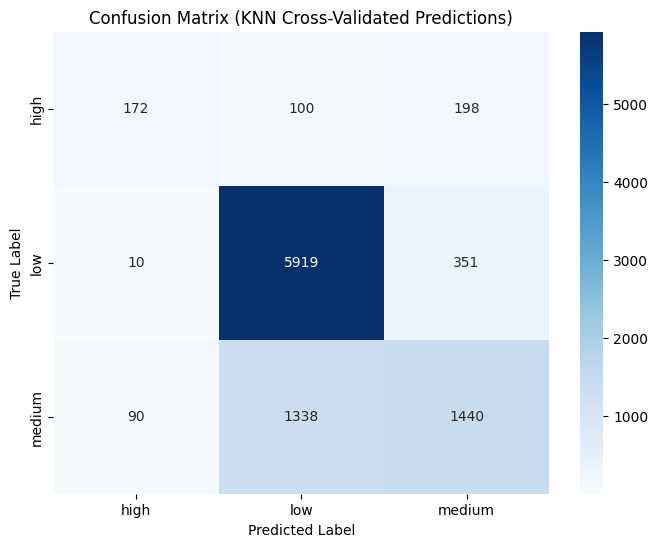


--- XGBoost Model Confusion Matrix (from previous run) ---


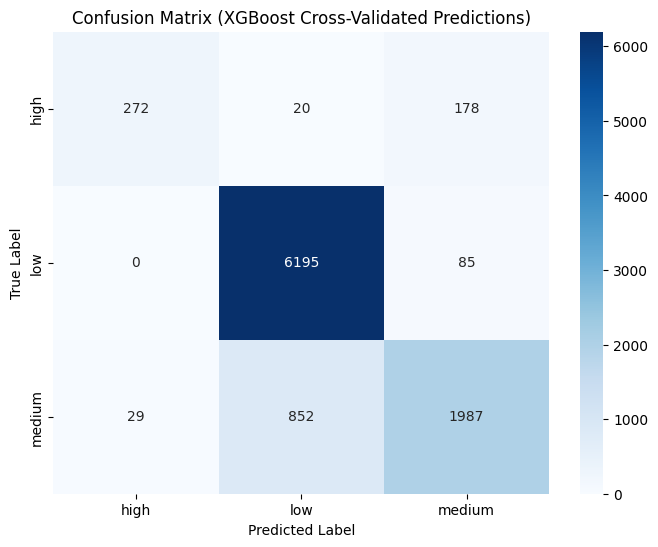

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- KNN Model Training and Evaluation ---
print("\n--- K-Nearest Neighbors (KNN) Model ---")

# Define KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Create a pipeline for KNN, reusing the preprocessing steps
knn_process = Pipeline([
    ("preprocess", preprocess),
    ("model", knn_model)
])

y_cv_pred_knn = np.zeros_like(y_encoded)
knn_cv_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X, y_encoded)):
    print(f"\n--- KNN Fold {fold+1} ---")
    X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
    y_train_fold, y_val_fold = y_encoded[train_idx], y_encoded[val_idx]

    knn_process.fit(X_train_fold, y_train_fold)
    fold_preds_knn = knn_process.predict(X_val_fold)
    y_cv_pred_knn[val_idx] = fold_preds_knn

    score_knn = f1_score(y_val_fold, fold_preds_knn, average='macro')
    knn_cv_scores.append(score_knn)
    print(f"KNN Fold {fold+1} F1 Macro Score: {score_knn:.4f}")

print("\nKNN Cross-validation F1 macro scores:", knn_cv_scores)
print("KNN Mean F1 macro:", np.mean(knn_cv_scores))
print("KNN Standard deviation:", np.std(knn_cv_scores).round(4))

print("\nKNN Overall Classification Report (Cross-Validated):")
print(classification_report(
    y_encoded,
    y_cv_pred_knn,
    target_names=le.classes_
))

# --- Confusion Matrix for KNN Model ---
cm_knn = confusion_matrix(y_encoded, y_cv_pred_knn)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix (KNN Cross-Validated Predictions)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# --- Confusion Matrix for XGBoost Model
print("\n--- XGBoost Model Confusion Matrix (from previous run) ---")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix (XGBoost Cross-Validated Predictions)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig('confusion_matrix.png')
plt.show()
